# Deep Learning Based Intrusion Detection System (IDS)

**Course:** Deep Learning  
**Project:** Intrusion Detection System  
**Technology:** Python, TensorFlow, Keras, Scikit-learn

## 1. Introduction

Modern computer networks face various cyber threats, including unauthorized access, Denial-of-Service (DoS) attacks, and network probing.

An Intrusion Detection System (IDS) monitors network traffic and identifies suspicious or malicious activities.

Traditional intrusion detection systems mainly depend on predefined rules. However, deep learning can learn patterns from network traffic data and help identify potentially malicious activities.

## 2. Project Objective

The main objective of this project is to develop a Deep Learning-based Intrusion Detection System that classifies network traffic into two categories:

- Normal Traffic (0)
- Attack Traffic (1)

The system uses a Feedforward Neural Network trained on network traffic data to distinguish between normal and malicious activities.

In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Deep Learning libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

# Check versions
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)
print("TensorFlow Version:", tf.__version__)

print("\nAll libraries imported successfully!")

Pandas Version: 2.2.3
NumPy Version: 2.4.6
TensorFlow Version: 2.21.0

All libraries imported successfully!


# 3. Data Acquisition and Dataset Loading

The KDD Cup 1999 dataset is used to train and evaluate
the Intrusion Detection System.

The dataset contains 41 input features describing
network connections and one target label indicating
whether a connection is normal or an attack.

We download the dataset from the official UCI KDD
repository and load it using Pandas.

In [6]:
# Download and load the KDD Cup 1999 dataset

from tensorflow.keras.utils import get_file

# Define column names
columns = [
    'duration', 'protocol_type', 'service', 'flag',
    'src_bytes', 'dst_bytes', 'land', 'wrong_fragment',
    'urgent', 'hot', 'num_failed_logins', 'logged_in',
    'num_compromised', 'root_shell', 'su_attempted',
    'num_root', 'num_file_creations', 'num_shells',
    'num_access_files', 'num_outbound_cmds',
    'is_host_login', 'is_guest_login', 'count',
    'srv_count', 'serror_rate', 'srv_serror_rate',
    'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
    'diff_srv_rate', 'srv_diff_host_rate',
    'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate',
    'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate',
    'label'
]

# Download dataset from GitHub
dataset_path = get_file(
    'kddcup.data_10_percent.gz',
    origin='https://raw.githubusercontent.com/saimukesh23/intrusion-detection-system/main/kddcup.data_10_percent.gz',
    cache_subdir='datasets',
    force_download=True
)

# Load dataset
df = pd.read_csv(
    dataset_path,
    names=columns,
    compression='gzip'
)

# Display basic information
print("Dataset loaded successfully!")
print("Total records:", len(df))
print("Total columns:", len(df.columns))

# Display first 5 records
display(df.head())

2144903/2144903 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset loaded successfully!
Total records: 494021
Total columns: 42


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label
0,0,tcp,http,SF,181,5450,0,0,0,0,...,9,1.0,0.0,0.11,0.0,0.0,0.0,0.0,0.0,normal.
1,0,tcp,http,SF,239,486,0,0,0,0,...,19,1.0,0.0,0.05,0.0,0.0,0.0,0.0,0.0,normal.
2,0,tcp,http,SF,235,1337,0,0,0,0,...,29,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0,normal.
3,0,tcp,http,SF,219,1337,0,0,0,0,...,39,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0,normal.
4,0,tcp,http,SF,217,2032,0,0,0,0,...,49,1.0,0.0,0.02,0.0,0.0,0.0,0.0,0.0,normal.


## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the
structure and characteristics of the dataset.

In this stage, we:
- Check the number of records and features.
- Examine the data types of each column.
- Identify missing values.
- Analyze the distribution of normal and attack traffic.

This helps us understand the dataset before applying
data preprocessing techniques.

Dataset Shape: (494021, 42)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 494021 entries, 0 to 494020
Data columns (total 42 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     494021 non-null  int64  
 1   protocol_type                494021 non-null  object 
 2   service                      494021 non-null  object 
 3   flag                         494021 non-null  object 
 4   src_bytes                    494021 non-null  int64  
 5   dst_bytes                    494021 non-null  int64  
 6   land                         494021 non-null  int64  
 7   wrong_fragment               494021 non-null  int64  
 8   urgent                       494021 non-null  int64  
 9   hot                          494021 non-null  int64  
 10  num_failed_logins            494021 non-null  int64  
 11  logged_in                    494021 non-null  int64  
 12  num_comp

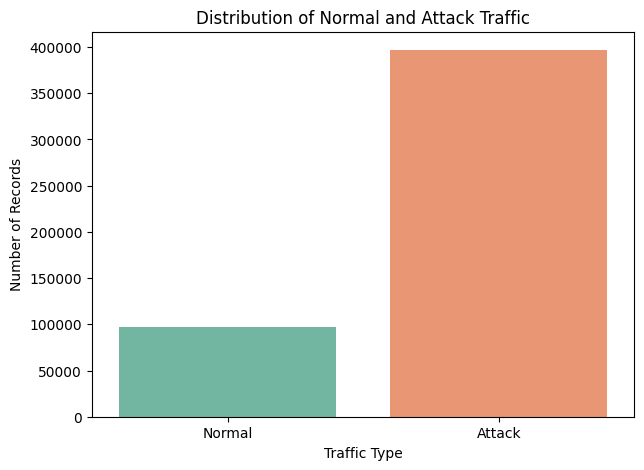

In [7]:
# Explore the dataset

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display column information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Display distribution of attack types
print("\nTop 10 Network Traffic Categories:")
print(df['label'].value_counts().head(10))

# Convert labels into Normal and Attack categories
binary_labels = df['label'].apply(
    lambda x: 'Normal' if x == 'normal.' else 'Attack'
)

# Count normal and attack records
traffic_counts = binary_labels.value_counts()

print("\nNormal vs Attack Traffic:")
print(traffic_counts)

# Visualize traffic distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    x=binary_labels,
    hue=binary_labels,
    palette='Set2',
    legend=False
)

plt.title("Distribution of Normal and Attack Traffic")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.show()

## 5. Data Preprocessing

Data preprocessing is performed to prepare the network
traffic dataset for Deep Learning.

The following operations are performed:

1. Convert attack labels into binary classes.
2. Separate input features and target labels.
3. Split the dataset into training and testing sets.
4. Convert categorical features into numerical values
   using One-Hot Encoding.
5. Normalize numerical features using StandardScaler.

These operations help the Neural Network process the
data efficiently and improve model performance.

In [8]:
# Import preprocessing libraries

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Separate input features and target labels

X = df.drop('label', axis=1)

# Convert labels into binary values
# 0 = Normal, 1 = Attack

y = (df['label'] != 'normal.').astype(int)

# Identify categorical and numerical columns

categorical_features = [
    'protocol_type', 'service', 'flag'
]

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Create preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False,
            dtype=np.float32
        ), categorical_features)
    ]
)

# Fit preprocessing on training data
X_train = preprocessor.fit_transform(X_train)

# Transform testing data
X_test = preprocessor.transform(X_test)

# Convert features into float32
X_train = X_train.astype(np.float32)
X_test = X_test.astype(np.float32)

# Display results
print("Data preprocessing completed successfully!")

print("\nTraining Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Labels Shape:", y_train.shape)
print("Testing Labels Shape:", y_test.shape)

print("\nNormal and Attack Labels:")
print(y_train.value_counts())

Data preprocessing completed successfully!

Training Features Shape: (370515, 116)
Testing Features Shape: (123506, 116)

Training Labels Shape: (370515,)
Testing Labels Shape: (123506,)

Normal and Attack Labels:
label
1    297557
0     72958
Name: count, dtype: int64


## 6. Deep Learning Model Architecture

A Feedforward Neural Network (FNN) is used to
classify network traffic into normal and attack categories.

The model consists of the following layers:

1. Input Layer: Accepts 116 input features.
2. Hidden Layer 1: 10 neurons with ReLU activation.
3. Hidden Layer 2: 50 neurons with ReLU activation.
4. Hidden Layer 3: 10 neurons with ReLU activation.
5. Output Layer: 1 neuron with Sigmoid activation.

### Model Compilation

- Loss Function: Binary Crossentropy
- Optimizer: Adam
- Evaluation Metric: Accuracy

Early Stopping is used to prevent overfitting
and restore the best model weights.

In [9]:
# Build the Feedforward Neural Network

model = Sequential()

# Input layer and hidden layers
model.add(Dense(10, input_shape=(X_train.shape[1],), activation='relu'))
model.add(Dense(50, activation='relu'))
model.add(Dense(10, activation='relu'))

# Output layer
model.add(Dense(1, activation='sigmoid'))

# Compile the model
model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# Configure Early Stopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    min_delta=1e-3,
    patience=5,
    verbose=1,
    restore_best_weights=True
)

# Display model architecture
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         1,170 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │           550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,241 (8.75 KB)

 Trainable params: 2,241 (8.75 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Train the Deep Learning Model

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=1024,
    callbacks=[early_stopping],
    verbose=1
)

print("\nModel training completed!")

Epoch 1/30
290/290 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9721 - loss: 0.1412 - val_accuracy: 0.9978 - val_loss: 0.0116
Epoch 2/30
290/290 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9983 - loss: 0.0072 - val_accuracy: 0.9987 - val_loss: 0.0064
Epoch 3/30
290/290 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9988 - loss: 0.0047 - val_accuracy: 0.9990 - val_loss: 0.0055
Epoch 4/30
290/290 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9991 - loss: 0.0040 - val_accuracy: 0.9991 - val_loss: 0.0046
Epoch 5/30
290/290 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9991 - loss: 0.0036 - val_accuracy: 0.9992 - val_loss: 0.0046
Epoch 6/30
290/290 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9992 - loss: 0.0033 - val_accuracy: 0.9993 - val_loss: 0.0045
Epoch 7/30
290/290 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9992 - loss: 0.0031 - val_accuracy: 0.9994 - val_loss: 0.0042
Epoch 8/30
290/290 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9993 - loss: 0.0028 - val_accuracy: 0

## 7. Model Performance Evaluation

In this stage, we evaluate the trained Deep Learning model using the testing dataset.

The model predicts whether network traffic is normal or malicious. We compare these predictions with the actual labels to measure the model's performance.

We calculate the following evaluation metrics:

- **Accuracy:** Measures the overall percentage of correct predictions.
- **Precision:** Measures how many predicted malicious activities are actually malicious.
- **Recall:** Measures how many actual malicious activities are correctly detected.
- **F1-score:** Provides a balance between Precision and Recall.

In [12]:
# Generate predictions using the trained model

y_pred_prob = model.predict(X_test)

# Convert probabilities into binary predictions
# 0 = Normal, 1 = Attack

y_pred = (y_pred_prob > 0.5).astype(int).flatten()

print("Model predictions generated successfully!")

print("\nFirst 10 Predicted Labels:")
print(y_pred[:10])

print("\nFirst 10 Actual Labels:")
print(y_test.iloc[:10].values)

3860/3860 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step
Model predictions generated successfully!

First 10 Predicted Labels:
[0 1 1 1 0 1 1 1 0 0]

First 10 Actual Labels:
[0 1 1 1 0 1 1 1 0 0]


In [13]:
# Calculate model accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Model Performance")
print("-------------------------")
print("Test Accuracy:", round(accuracy * 100, 2), "%")

Model Performance
-------------------------
Test Accuracy: 99.91 %


In [14]:
# Generate classification report

print("Classification Report")
print("-------------------------")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Normal', 'Attack']
    )
)

Classification Report
-------------------------
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     24320
      Attack       1.00      1.00      1.00     99186

    accuracy                           1.00    123506
   macro avg       1.00      1.00      1.00    123506
weighted avg       1.00      1.00      1.00    123506



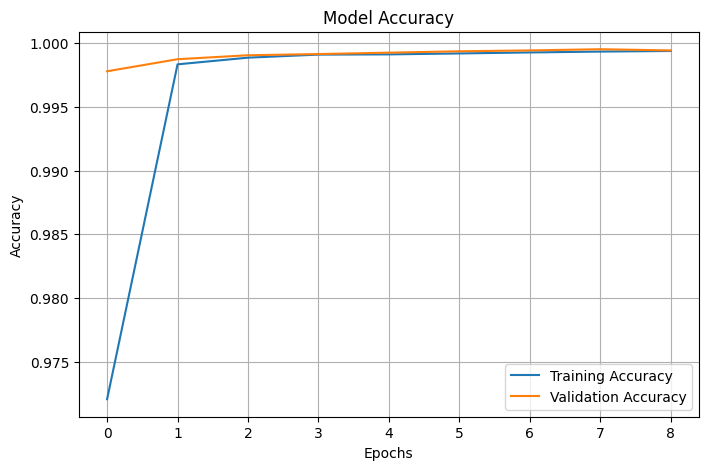

In [15]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(True)

plt.show()

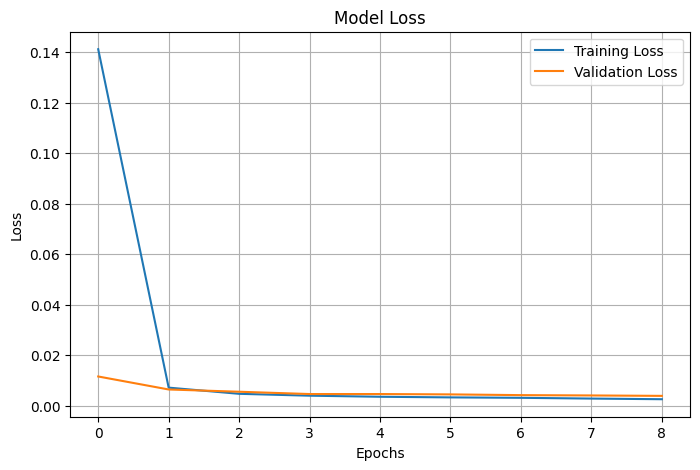

In [16]:
# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)

plt.show()

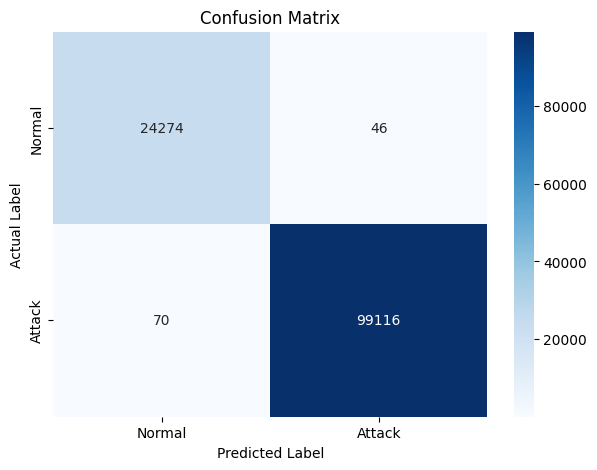

Confusion Matrix:
[[24274    46]
 [   70 99116]]


In [17]:
# Generate confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Attack'],
    yticklabels=['Normal', 'Attack']
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

print("Confusion Matrix:")
print(cm)

## 8. Sample Network Traffic Predictions

In this stage, the trained Deep Learning model is tested using sample network traffic records from the testing dataset.

The model predicts whether each network connection represents normal activity or a potential attack.

The prediction results are displayed along with the actual labels to demonstrate the classification capability of the Intrusion Detection System.

In [18]:
# Predict sample network traffic records

sample_size = 10

sample_data = X_test[:sample_size]

sample_predictions = model.predict(sample_data, verbose=0)

sample_predictions = (
    sample_predictions > 0.5
).astype(int).flatten()

actual_labels = y_test.iloc[:sample_size].values

# Convert numerical predictions into readable labels

class_names = {
    0: 'Normal',
    1: 'Attack'
}

print("Sample Network Traffic Predictions")
print("=" * 55)

for i in range(sample_size):

    predicted_class = class_names[sample_predictions[i]]
    actual_class = class_names[actual_labels[i]]

    print(f"\nRecord {i + 1}")
    print("Predicted:", predicted_class)
    print("Actual:   ", actual_class)

    if sample_predictions[i] == actual_labels[i]:
        print("Result: Correct Prediction")
    else:
        print("Result: Incorrect Prediction")

Sample Network Traffic Predictions

Record 1
Predicted: Normal
Actual:    Normal
Result: Correct Prediction

Record 2
Predicted: Attack
Actual:    Attack
Result: Correct Prediction

Record 3
Predicted: Attack
Actual:    Attack
Result: Correct Prediction

Record 4
Predicted: Attack
Actual:    Attack
Result: Correct Prediction

Record 5
Predicted: Normal
Actual:    Normal
Result: Correct Prediction

Record 6
Predicted: Attack
Actual:    Attack
Result: Correct Prediction

Record 7
Predicted: Attack
Actual:    Attack
Result: Correct Prediction

Record 8
Predicted: Attack
Actual:    Attack
Result: Correct Prediction

Record 9
Predicted: Normal
Actual:    Normal
Result: Correct Prediction

Record 10
Predicted: Normal
Actual:    Normal
Result: Correct Prediction


In [19]:
# Calculate sample prediction performance

correct_predictions = np.sum(
    sample_predictions == actual_labels
)

incorrect_predictions = sample_size - correct_predictions

print("Sample Prediction Summary")
print("=" * 40)

print("Total Samples:", sample_size)
print("Correct Predictions:", correct_predictions)
print("Incorrect Predictions:", incorrect_predictions)

print(
    "Sample Accuracy:",
    round((correct_predictions / sample_size) * 100, 2),
    "%"
)

Sample Prediction Summary
Total Samples: 10
Correct Predictions: 10
Incorrect Predictions: 0
Sample Accuracy: 100.0 %


## 9. Final Model Performance Summary

The Intrusion Detection System was evaluated using the testing dataset.

The model performance was measured using accuracy, precision, recall and F1-score.

Training and validation graphs were generated to visualize the learning process. A confusion matrix was also used to analyze correct and incorrect classifications.

Sample network traffic records were tested to demonstrate the model's ability to distinguish between normal and malicious network activities.

In [20]:
# Display final model performance

print("=" * 50)
print("INTRUSION DETECTION SYSTEM - FINAL RESULTS")
print("=" * 50)

print("\nDataset Information")
print("-------------------------")
print("Total Dataset Records:", len(df))
print("Training Records:", len(y_train))
print("Testing Records:", len(y_test))

print("\nModel Information")
print("-------------------------")
print("Model Type: Feedforward Neural Network")
print("Hidden Layers: 3")
print("Output Classes: Normal and Attack")
print("Optimizer: Adam")
print("Loss Function: Binary Crossentropy")

print("\nPerformance Results")
print("-------------------------")
print("Test Accuracy:", round(accuracy * 100, 2), "%")

print("\nTraining Epochs Completed:", len(history.history['loss']))

print("\nProject Status: Completed Successfully!")
print("=" * 50)

INTRUSION DETECTION SYSTEM - FINAL RESULTS

Dataset Information
-------------------------
Total Dataset Records: 494021
Training Records: 370515
Testing Records: 123506

Model Information
-------------------------
Model Type: Feedforward Neural Network
Hidden Layers: 3
Output Classes: Normal and Attack
Optimizer: Adam
Loss Function: Binary Crossentropy

Performance Results
-------------------------
Test Accuracy: 99.91 %

Training Epochs Completed: 9

Project Status: Completed Successfully!
